In [1]:
import os
import time

import geopandas as gpd
import matplotlib.pyplot as plt
import nivapy3 as nivapy
import numpy as np
import pandas as pd
import rasterio
from osgeo import gdal
from rasterio.features import geometry_mask, rasterize
from rasterio.windows import from_bounds
from rasterstats import zonal_stats
from shapely.ops import unary_union

gdal.UseExceptions()

In [2]:
eng = nivapy.da.connect_postgis()

Connection successful.


# ML for water quality: static catchment properties

**Run this code on a large machine!**

Deriving catchment properties based on commonly available datasets. The following properties are included:

 * Catchment elevation statistics (m; derived from 20 or 40 m DTM)
 * Catchment slope statistics (degrees; derived from 20 or 40 m DTM)
 * Sentinel2 average summer NDVI for recent period

**To do in next iteration: replace AR50 with ESA World Land Cover 2021 for waterbody and agriculture masking, for a workflow that works outside Norway**

 * (Not implemented yet: Drainage density using elvis network and catchment area. Apparently very scale dependent though - higher in headwaters)

# User input

In [3]:
cat_fpath = r"/home/jovyan/shared/common/norsink/spatial/monitored_chem_catchments/catchments_vm-rivs-quant-oc_v3-full.gpkg"

cat_id_col = "site_code"

# Raster resolution
raster_res = 40  # metres

# Paths to rasters
dem_path = f"/home/jovyan/shared/common/01_datasets/spatial/dtm_merged_utm33/dtm_{raster_res}m/norway_kartverket_{raster_res}m_dtm_utm_z33.tif"
slp_path = f"/home/jovyan/shared/common/01_datasets/spatial/dtm_merged_utm33/dtm_{raster_res}m/norway_kartverket_{raster_res}m_slopedeg_utm_z33.tif"
ndvi_path = f"/home/jovyan/shared/common/01_datasets/spatial/sentinel2_ndvi_static/S2_NDVI_Norway_2020-2024_DOY182-227_50m_median-count_filled_3857.tif"

# Output folder (csv added here)
catchment_set = "monitored-oc-catchs"  # for filenaming
out_folder = r"/home/jovyan/shared/common/norsink/vm_catchments_data"

# Read catchment boundaries

In [4]:
# Read catchments
cat_gdf = gpd.read_file(cat_fpath)

# cat_gdf = cat_gdf[:5].copy()
cat_gdf.head()

,site_code,lon,lat,site_id,Name,start_year,end_year,n_years,n_samples,av_freq,area_km2,geometry
0,001-119928,11.653745,59.476520,119928,Oppstrøms Bommen RA,2011,2025,14.0,14,1.00,1008.505005,"POLYGON ((306680 6664180, 306760 6664180, 3067..."
1,001-119929,11.654461,59.472300,119929,Nedstrøms Bommen RA,2011,2025,14.0,14,1.00,1009.065359,"POLYGON ((306680 6664180, 306760 6664180, 3067..."
2,001-30653,11.437438,59.070299,30653,YSTE YSTEHEDEBEKKEN,1987,1987,1.0,4,4.00,6.702626,"POLYGON ((298520 6555300, 298640 6555300, 2986..."
3,001-30683,11.295421,59.121185,30683,"Unnebergbekken, UNNE",1987,2016,29.1,5,0.17,15.372746,"POLYGON ((290660 6567260, 290680 6567260, 2906..."
4,001-30687,11.528412,58.987892,30687,ØRB2 ØRBEKKEN,1991,1991,1.0,4,4.00,42.290760,"POLYGON ((305560 6548480, 305560 6548500, 3055..."


# Define functions

In [5]:
def compute_zonal_stats(
    cat_gdf,
    raster_path,
    stats_list,
    cat_id_col,
    prefix="",
    buffer=1000,
    min_frac=0.0,
    use_land_mask=False,
    land_geom=None,
    threshold_stats=None,
    mask_array=None,
    mask_mode="exclude",
    plot=False,
    band=1,  # Which band to read in the input raster. Default 1
):
    # ----------------------------
    # Helpers
    # ----------------------------
    def cname(p, s):
        return f"{p}_{s}" if p else s

    # ----------------------------
    # 1. Read raster subset
    # ----------------------------
    xmin, ymin, xmax, ymax = cat_gdf.total_bounds
    xmin -= buffer
    ymin -= buffer
    xmax += buffer
    ymax += buffer

    with rasterio.open(raster_path) as src:
        window = from_bounds(xmin, ymin, xmax, ymax, src.transform)
        window = window.round_offsets().round_lengths()

        raster = src.read(band, window=window)
        transform = src.window_transform(window)
        nodata = src.nodata if src.nodata is not None else np.nan

    # ----------------------------
    # 2. Align mask safely
    # ----------------------------
    if mask_array is not None:
        row_off = int(window.row_off)
        col_off = int(window.col_off)
        h = int(window.height)
        w = int(window.width)

        mask_window = mask_array[row_off:row_off + h, col_off:col_off + w]

        # enforce exact shape match
        mask_window = mask_window[:raster.shape[0], :raster.shape[1]]
    else:
        mask_window = None

    # ----------------------------
    # 3. Apply optional land mask
    # ----------------------------
    raster_base = raster

    if use_land_mask:
        from rasterio.features import geometry_mask

        land_mask = geometry_mask(
            [land_geom],
            transform=transform,
            invert=True,
            out_shape=raster.shape,
        )

        raster_base = np.where(land_mask, raster_base, nodata)

    # ----------------------------
    # 4. Compute denominator (valid pixels)
    # ----------------------------
    zs_base = zonal_stats(
        cat_gdf,
        raster_base,
        affine=transform,
        stats=["count"],
        nodata=nodata,
        raster_out=False,
    )

    total_base_arr = np.array([z.get("count") or 0 for z in zs_base])

    # ----------------------------
    # 5. Apply analysis mask
    # ----------------------------
    raster_used = raster_base.copy()

    if mask_window is not None:
        if mask_mode == "exclude":
            raster_used[mask_window != 0] = nodata
        else:
            raster_used[mask_window == 0] = nodata

    # ----------------------------
    # 6. Main zonal stats
    # ----------------------------
    zs = zonal_stats(
        cat_gdf,
        raster_used,
        affine=transform,
        stats=stats_list + ["count"],
        nodata=nodata,
        raster_out=False,
    )

    # ----------------------------
    # 7. Threshold stats
    # ----------------------------
    thresh_results = {}

    if threshold_stats is not None:
        ops = {
            "lt": np.less,
            "le": np.less_equal,
            "gt": np.greater,
            "ge": np.greater_equal,
        }

        for ts in threshold_stats:
            name = ts["name"]
            op = ops[ts["op"]]
            val = ts["value"]

            cond = op(raster_used, val).astype("uint8")

            zs_thresh = zonal_stats(
                cat_gdf,
                cond,
                affine=transform,
                stats=["sum"],
                nodata=0,
                raster_out=False,
            )

            thresh_results[name] = np.array(
                [(z.get("sum") or 0) for z in zs_thresh]
            )

            del cond  # free memory

    # ----------------------------
    # 8. Combine results
    # ----------------------------
    results = []

    for i, s in enumerate(zs):
        row = {}

        total_base = total_base_arr[i]

        # ---- basic stats
        for stat in stats_list:
            val = s.get(stat)
            row[stat] = val if val is not None else np.nan

        # ---- valid fraction
        valid_count = s.get("count") or 0
        row["valid_frac"] = (
            valid_count / total_base if total_base > 0 else np.nan
        )

        row["total_count"] = total_base

        # ---- threshold stats (your preferred behavior)
        if threshold_stats is not None:
            for ts in threshold_stats:
                name = ts["name"]
                cnt = thresh_results[name][i]

                if total_base > 0:
                    row[f"{name}_count"] = cnt
                    row[f"{name}_frac"] = cnt / total_base
                else:
                    row[f"{name}_count"] = np.nan
                    row[f"{name}_frac"] = np.nan

        results.append(row)

    # ----------------------------
    # 9. Assign outputs
    # ----------------------------
    for stat in stats_list:
        cat_gdf[cname(prefix, stat)] = [r[stat] for r in results]

    cat_gdf[cname(prefix, "valid_frac")] = [r["valid_frac"] for r in results]
    cat_gdf["total_count"] = [r["total_count"] for r in results]

    if threshold_stats is not None:
        for ts in threshold_stats:
            name = ts["name"]

            cat_gdf[cname(prefix, f"{name}_count")] = [
                r[f"{name}_count"] for r in results
            ]
            cat_gdf[cname(prefix, f"{name}_frac")] = [
                r[f"{name}_frac"] for r in results
            ]

    # ----------------------------
    # 10. Apply min_frac filter
    # ----------------------------
    vf_col = cname(prefix, "valid_frac")
    # bad = cat_gdf[vf_col] < min_frac
    bad = (cat_gdf[vf_col] < min_frac) | (cat_gdf["total_count"] == 0)

    stat_cols = [cname(prefix, s) for s in stats_list]

    if threshold_stats is not None:
        stat_cols += [
            cname(prefix, f"{ts['name']}_frac") for ts in threshold_stats
        ]

    cat_gdf.loc[bad, stat_cols] = np.nan

    # ----------------------------
    # 11. Reporting
    # ----------------------------
    n_total = len(cat_gdf)
    n_bad = bad.sum()
    frac = n_bad / n_total if n_total > 0 else np.nan

    print(f"{prefix}: {n_bad}/{n_total} catchments have <{min_frac} proportion valid pixels ({frac:.1%}), replaced stats with NaNs")
    print(f"{prefix}: {np.sum(total_base_arr == 0)} catchments with no valid pixels")

    # ----------------------------
    # 12. Cleanup
    # ----------------------------
    del raster, raster_base, raster_used, zs, zs_base
    if mask_array is not None:
        del mask_window

    import gc
    gc.collect()

    return cat_gdf, stat_cols

# Check crs

N.B. don't expect ndvi to be the same - dealt with below.

In [7]:
# Check all crs are the same

with rasterio.open(slp_path) as src:
    slope_crs = src.crs

with rasterio.open(dem_path) as src:
    dem_crs = src.crs

# with rasterio.open(ndvi_path) as src:
#     ndvi_crs = src.crs


crs_set = {
    str(slope_crs),
    str(dem_crs),
    # str(ndvi_crs),    
    # str(land_gdf.crs),
    str(cat_gdf.crs),
}

assert len(crs_set) == 1, f"CRS mismatch detected: {crs_set}"

AssertionError: CRS mismatch detected: {'EPSG:25833', 'EPSG:3857'}

# Slope

## Slope stats over whole catchment

In [ ]:
# # statistics to compute
# slope_stats_list = [
#     "mean",
#     "std",
#     "median",
#     "percentile_5",
#     "percentile_95",
#     "min",
#     "max",
# ]

# t0 = time.perf_counter()

# slope_gdf = cat_gdf[["site_code", "Name", "geometry"]].copy()

# slope_gdf, slope_stat_cols = compute_zonal_stats(
#     cat_gdf=slope_gdf,
#     raster_path=slp_path,
#     stats_list=slope_stats_list,
#     cat_id_col=cat_id_col,
#     land_geom=None,
#     prefix="slope_deg",
#     buffer=1000,
#     min_frac=0.0,  # If 0, don't remove any
#     use_land_mask=False,
#     plot=False,
#     threshold_stats=[
#         {"name": "lt2", "op": "lt", "value": 2},
#         {"name": "lt5", "op": "lt", "value": 5},
#     ],
# )

# t1 = time.perf_counter()
# print(f"Time: {t1 - t0:.2f}s")

# # print(slope_stat_cols)
# slope_gdf[[cat_id_col]+slope_stat_cols]
# # slope_gdf.describe()

In [46]:
# slope_gdf.describe()

,slope_deg_mean,slope_deg_std,slope_deg_median,slope_deg_percentile_5,slope_deg_percentile_95,slope_deg_min,slope_deg_max,slope_deg_valid_frac,total_count,slope_deg_lt2_count,slope_deg_lt2_frac,slope_deg_lt5_count,slope_deg_lt5_frac
count,8482.000000,8482.000000,8482.000000,8482.000000,8482.000000,8482.000000,8482.000000,8482.0,8.482000e+03,8.482000e+03,8482.000000,8.482000e+03,8482.000000
mean,10.054703,6.798111,8.800763,1.429277,23.041370,0.103325,41.496659,1.0,2.325363e+05,3.943933e+04,0.135432,9.369595e+04,0.347205
std,5.115042,3.058115,5.050235,1.339821,10.426759,0.289138,17.289040,0.0,1.296716e+06,2.509010e+05,0.127287,5.889037e+05,0.210890
min,0.263755,0.137976,0.240793,0.000000,0.527520,0.000000,0.849482,1.0,2.040000e+02,0.000000e+00,0.000000,0.000000e+00,0.000000
25%,6.576344,4.598492,5.510260,0.573365,15.573688,0.000366,28.409079,1.0,1.424000e+03,1.190000e+02,0.055556,4.080000e+02,0.190036
50%,9.022896,6.313412,7.713648,1.110272,21.269325,0.009778,39.683254,1.0,5.538500e+03,5.790000e+02,0.099658,1.657500e+03,0.307992
75%,12.401927,8.547180,10.840158,1.859293,29.132576,0.089078,54.460027,1.0,3.246025e+04,3.728500e+03,0.165069,9.526000e+03,0.453714
max,40.815123,21.270218,43.679131,23.307161,69.798668,8.514078,81.272041,1.0,2.608856e+07,4.828769e+06,1.000000,1.183714e+07,1.000000


In [40]:
# # Save
# slope_fpath = os.path.join(out_folder, f"{catchment_set}_stats_static_slope.csv")
# slope_gdf.drop("geometry", axis=1).to_csv(slope_fpath, index=False)

In [ ]:
# slope_gdf[slope_stat_cols].plot(kind="box", figsize=(10, 6))
# plt.title("Slope stats")
# plt.xticks(rotation=90)
# plt.ylabel("Slope (deg)")
# plt.show()

In [42]:
# col = "slope_deg_mean"
# # col = "slope_deg_percentile_95"

# fig, ax = plt.subplots(figsize=(10, 10))
# slope_gdf.plot(column=col, ax=ax, legend=True, cmap='viridis', legend_kwds={"shrink": 0.5, "aspect": 20})
# slope_gdf.boundary.plot(ax=ax, color="black", linewidth=0.3)
# # # Unioned land mask
# # gpd.GeoSeries([land_geom]).boundary.plot(
# #     ax=ax, color="white", linewidth=1
# # )
# plt.title(col)
# plt.show()

## Slope on non-agricultural land

### AR50 land cover

In [17]:
# Read in AR50 & rename
class_dict = {
    "10": "bebygd",
    "20": "jordbruk",
    "30": "skog",
    "50": "snaumark",
    "60": "myr",
    "70": "bre",
    "81": "ferskvann",
    "82": "hav",
    "99": "ikke-kartlagt",
}

ar50_gdf = nivapy.da.read_postgis("physical", "norway_nibio_ar50_poly", eng)
ar50_gdf = ar50_gdf[["artype", "geom"]]

# ensure geometry column is correct
ar50_gdf = ar50_gdf.rename(columns={"geom": "geometry"}).set_geometry("geometry")
ar50_gdf["artype"] = ar50_gdf["artype"].replace(class_dict)

In [18]:
# Make agriculture mask

# read raster metadata (no need to read full array)
with rasterio.open(slp_path) as src:
    raster_crs = src.crs
    shape = (src.height, src.width)
    transform = src.transform

# reproject AR50 if needed
if ar50_gdf.crs != raster_crs:
    ar50_gdf = ar50_gdf.to_crs(raster_crs)

# make agriculture geometry
agri_geom = ar50_gdf.loc[ar50_gdf["artype"] == "jordbruk", "geometry"]
agri_geom = unary_union(agri_geom)

# rasterize to make mask
agri_mask = rasterize(
    [(agri_geom, 1)], out_shape=shape, transform=transform, fill=0, dtype="uint8"
)

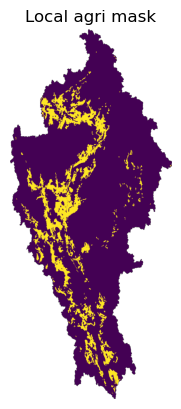

In [50]:
# Quick check of mask for one catchment with lots of agriculture

geom = cat_gdf.iloc[0].geometry

# get bounding box
xmin, ymin, xmax, ymax = geom.bounds

# open raster to get transform + window
with rasterio.open(slp_path) as src:
    window = from_bounds(xmin, ymin, xmax, ymax, src.transform)
    transform_window = src.window_transform(window)

    # slice mask directly
    mask_crop = agri_mask[
        int(window.row_off) : int(window.row_off + window.height),
        int(window.col_off) : int(window.col_off + window.width),
    ]

# create mask only for the small window
mask_geom = geometry_mask(
    [geom],
    transform=transform_window,
    invert=True,
    out_shape=mask_crop.shape,
)

local = np.where(mask_geom, mask_crop, np.nan)

plt.imshow(local)
plt.title("Local agri mask")
plt.axis("off")
plt.show()

### Zonal stats

In [43]:
# statistics to compute
slope_stats_list = [
    "mean",
    "std",
    "median",
    "percentile_5",
    "percentile_95",
    "min",
    "max",
]

t0 = time.perf_counter()

slope_nonagri_gdf = cat_gdf[["site_code", "Name", "geometry"]].copy()

slope_nonagri_gdf, slope_noagri_stat_cols = compute_zonal_stats(
    cat_gdf=slope_nonagri_gdf,
    raster_path=slp_path,
    stats_list=slope_stats_list,
    cat_id_col=cat_id_col,
    land_geom=None,
    prefix="slope_nonagri_deg",
    buffer=1000,
    min_frac=0,  # If 0, don't remove any
    use_land_mask=False,
    plot=False,
    threshold_stats=[
        {"name": "lt2", "op": "lt", "value": 2},
        {"name": "lt5", "op": "lt", "value": 5},
    ],
    mask_array=agri_mask,
    mask_mode="exclude",  # include: keep pixels where mask==1, i.e. in this case agri
)

t1 = time.perf_counter()
print(f"Time: {t1 - t0:.2f}s")

# print(slope_stat_cols)
# slope_nonagri_gdf
# slope_nonagri_gdf[[cat_id_col]+slope_stat_cols]
slope_nonagri_gdf.describe()

slope_nonagri_deg: 0/8482 catchments have <0 proportion valid pixels (0.0%), replaced stats with NaNs
slope_nonagri_deg: 0 catchments with no valid pixels
Time: 1073.01s


,slope_nonagri_deg_mean,slope_nonagri_deg_std,slope_nonagri_deg_median,slope_nonagri_deg_percentile_5,slope_nonagri_deg_percentile_95,slope_nonagri_deg_min,slope_nonagri_deg_max,slope_nonagri_deg_valid_frac,total_count,slope_nonagri_deg_lt2_count,slope_nonagri_deg_lt2_frac,slope_nonagri_deg_lt5_count,slope_nonagri_deg_lt5_frac
count,8481.000000,8481.000000,8481.000000,8481.000000,8481.000000,8481.000000,8481.000000,8482.000000,8.482000e+03,8.482000e+03,8482.000000,8.482000e+03,8482.000000
mean,10.481572,6.867620,9.283710,1.604133,23.523579,0.130286,41.482604,0.887776,2.325363e+05,4.581910e+04,0.213817,9.756113e+04,0.387804
std,5.274599,2.997387,5.236048,1.607664,10.388778,0.367710,17.313328,0.170809,1.296716e+06,2.942502e+05,0.190068,6.132622e+05,0.221559
min,0.287591,0.183603,0.232186,0.000000,0.675702,0.000000,0.818906,0.000000,2.040000e+02,0.000000e+00,0.000000,0.000000e+00,0.000000
25%,6.978338,4.719215,5.893564,0.625935,16.098200,0.000366,28.410688,0.860807,1.424000e+03,2.210000e+02,0.087971,4.842500e+02,0.222716
50%,9.364429,6.397779,8.113046,1.226092,21.731764,0.011213,39.683254,0.964832,5.538500e+03,9.635000e+02,0.149371,1.898500e+03,0.341019
75%,12.850347,8.567671,11.381905,2.049226,29.532084,0.112789,54.461712,0.995194,3.246025e+04,5.375500e+03,0.269143,1.059225e+04,0.509205
max,42.910849,19.549633,45.001820,23.307161,70.002365,8.514078,81.272041,1.000000,2.608856e+07,6.094587e+06,1.000000,1.246608e+07,1.000000


In [44]:
# Manual check for 1st catchment, comparing slopes for full catch vs agri and natural land. Looks sensible
# f_agri is 0.135, so what would we expect the weighted mean and median slopes to be?
# Medians for all natural (i.e. "exclude") and only agri land (i.e. "include")
# 4.82*(1-0.135) + 2.44*0.135  # Medians. = 4.5. Actual value 4.42
# 5.92*(1-0.135) + 3.10*0.135  # Means. =5.54. Actual value 5.54.

# Manual check of thresholds. See how real values compare to weighted
# averages to see how flat agri land is. For catch1, see it is flatter than natural
# (80% of it <5deg, vs 50% for natural)
# i.e. work out how flat agri land is:
# cat_gdf["lt5_given_agri"] = (
#     cat_gdf["lt5_frac_ag"] / cat_gdf["agri_frac"]
# )

In [45]:
# Save
slope_noagri_fpath = os.path.join(
    out_folder, f"{catchment_set}_stats_static_slope-nonagri.csv"
)
slope_nonagri_gdf.drop("geometry", axis=1).to_csv(slope_noagri_fpath, index=False)

In [ ]:
# slope_nonagri_gdf[slope_stat_cols].plot(kind="box", figsize=(10, 6))
# plt.title("Slope stats")
# plt.xticks(rotation=90)
# plt.ylabel("Slope (deg)")
# plt.show()

In [ ]:
# col = "slope_nonagri_deg_mean"
# # col = "slope_nonagri_deg_percentile_95"

# fig, ax = plt.subplots(figsize=(10, 10))
# slope_nonagri_gdf.plot(column=col, ax=ax, legend=True, cmap='viridis', legend_kwds={"shrink": 0.5, "aspect": 20})
# slope_nonagri_gdf.boundary.plot(ax=ax, color="black", linewidth=0.3)
# # # Unioned land mask
# # gpd.GeoSeries([land_geom]).boundary.plot(
# #     ax=ax, color="white", linewidth=1
# # )
# plt.title(col)
# plt.show()

# Elevation

In [48]:
# statistics to compute
elev_stats_list = [
    "mean",
    "std",
    "median",
    "percentile_5",
    "percentile_95",
    "min",
    "max",
]

elev_gdf = cat_gdf[["site_code", "Name", "geometry"]].copy()

elev_gdf, elev_stat_cols = compute_zonal_stats(
    cat_gdf=elev_gdf,
    raster_path=dem_path,
    stats_list=elev_stats_list,
    cat_id_col=cat_id_col,
    land_geom=None,
    prefix="elev_m",
    buffer=1000,
    min_frac=0.0,
    use_land_mask=False,
    plot=False,
)

elev_gdf[elev_stat_cols].describe()

elev_m: 0/8482 catchments have <0.0 proportion valid pixels (0.0%), replaced stats with NaNs
elev_m: 0 catchments with no valid pixels


,elev_m_mean,elev_m_std,elev_m_median,elev_m_percentile_5,elev_m_percentile_95,elev_m_min,elev_m_max
count,8482.000000,8482.000000,8482.000000,8482.000000,8482.000000,8482.000000,8482.000000
mean,420.625914,113.114449,421.394819,237.727411,601.347950,166.600934,707.924842
std,329.522083,93.531832,339.031340,251.177470,429.436112,225.079482,518.544404
min,5.506085,0.854037,3.000966,-3.654467,9.475938,-10.070532,10.850326
25%,160.911120,40.541128,154.027733,60.997398,247.100037,17.114725,287.521698
50%,310.399308,84.411700,304.794586,146.201279,481.122604,78.800186,556.639008
75%,624.897798,159.003736,627.376022,313.438080,908.658798,198.254585,1028.117401
max,1767.029715,566.954870,1765.496460,1436.994873,2122.247070,1352.343872,2456.297607


In [49]:
# Save
elev_fpath = os.path.join(out_folder, f"{catchment_set}_stats_static_elevation.csv")
elev_gdf.drop("geometry", axis=1).to_csv(elev_fpath, index=False)

In [63]:
# Check catchments with elevation < 0
elev_gdf[elev_gdf['elev_m_min'] < -0.1]

,site_code,Name,geometry,elev_m_mean,elev_m_std,elev_m_median,elev_m_percentile_5,elev_m_percentile_95,elev_m_min,elev_m_max,elev_m_valid_frac,total_count
3,001-30683,"Unnebergbekken, UNNE","POLYGON ((290660 6567260, 290680 6567260, 2906...",71.492674,32.613888,72.106972,13.624030,122.802887,-5.827085,154.368256,1.0,9709
29,001-60271,Unnebergbekken,"POLYGON ((290660 6567260, 290680 6567260, 2906...",66.187834,33.441099,65.794136,12.157127,120.861015,-5.827085,154.368256,1.0,11795
33,001-63073,Unnebergbekken,"POLYGON ((290660 6567260, 290680 6567260, 2906...",65.423038,33.598684,64.965210,11.821891,120.680969,-5.827085,154.368256,1.0,12118
61,001-81711,Unnebergbekken,"POLYGON ((290660 6567260, 290680 6567260, 2906...",72.043884,32.261489,72.553032,14.203879,122.901627,-5.827085,154.368256,1.0,9619
62,001-81712,Unnebergbekken,"POLYGON ((290660 6567260, 290680 6567260, 2906...",72.420808,32.008073,72.775749,14.795741,122.950035,-5.827085,154.368256,1.0,9559
3008,015-104858,Kråkelundbekken,"POLYGON ((188460 6604960, 188460 6604980, 1884...",797.815113,400.946119,868.660156,91.143028,1291.473389,-0.276322,1531.096558,1.0,3468115
3075,015-28489,Gloppe bru,"POLYGON ((188460 6604960, 188460 6604980, 1884...",797.276848,401.319318,868.118530,90.150703,1291.432739,-0.309145,1531.096558,1.0,3470555
3122,015-51131,Klåstad,"POLYGON ((223360 6557660, 223420 6557660, 2234...",23.938668,14.538957,25.846251,-3.654467,42.351273,-9.003549,78.994431,1.0,301
3143,015-60552,Brattås 1,"POLYGON ((223360 6557660, 223420 6557660, 2234...",20.825759,15.903284,20.543903,0.219274,49.954967,-9.003549,78.994431,1.0,584
3593,016-79735,Barkevikbekken,"POLYGON ((205580 6557080, 205620 6557080, 2056...",64.292062,40.001505,62.571472,9.115095,133.212082,-10.070532,180.341064,1.0,7486


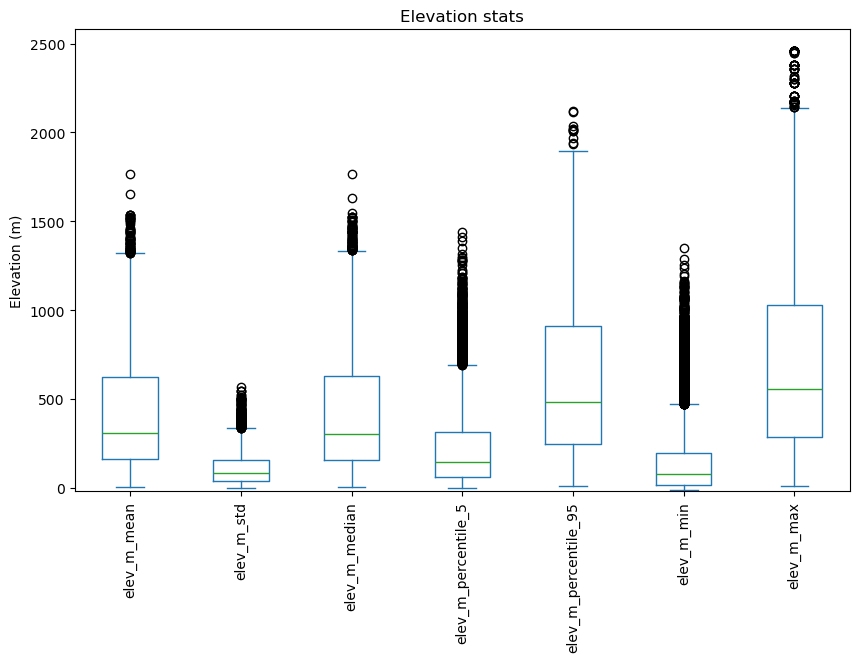

In [56]:
elev_gdf[elev_stat_cols].plot(kind="box", figsize=(10, 6))
plt.title("Elevation stats")
plt.xticks(rotation=90)
plt.ylabel("Elevation (m)")
plt.ylim(ymin=-20)
plt.show()

In [ ]:
col = "elev_m_mean"

fig, ax = plt.subplots(figsize=(10, 10))
elev_gdf[:10].plot(column=col, ax=ax, legend=True, cmap='viridis', legend_kwds={"shrink": 0.5, "aspect": 20})
elev_gdf[:10].boundary.plot(ax=ax, color="black", linewidth=0.3)

# # Unioned land mask
# gpd.GeoSeries([land_geom]).boundary.plot(
#     ax=ax, color="white", linewidth=1
# )
plt.title(col)
plt.show()

# Sentinel 2 median summer NDVI

Mask permanent waterbodies with a bit of a buffer

In [6]:
# reproject catchments to raster CRS
cat_gdf_3857 = cat_gdf.to_crs("EPSG:3857")

## Read in AR50 and make water & ocean mask

In [7]:
# if 'ar50_gdf' not in locals():
#     # Read in AR50 & rename
#     class_dict = {
#         "10": "bebygd",
#         "20": "jordbruk",
#         "30": "skog",
#         "50": "snaumark",
#         "60": "myr",
#         "70": "bre",
#         "81": "ferskvann",
#         "82": "hav",
#         "99": "ikke-kartlagt",
#     }
    
#     ar50_gdf = nivapy.da.read_postgis("physical", "norway_nibio_ar50_poly", eng)
#     ar50_gdf = ar50_gdf[["artype", "geom"]]
    
#     # ensure geometry column is correct
#     ar50_gdf = ar50_gdf.rename(columns={"geom": "geometry"}).set_geometry("geometry")
#     ar50_gdf["artype"] = ar50_gdf["artype"].replace(class_dict)

In [9]:
# water_buffer = 10  # metres (EPSG:3857)

# # Read raster metadata
# with rasterio.open(ndvi_path) as src:
#     raster_crs = src.crs
#     shape = (src.height, src.width)
#     transform = src.transform

# # Reproject AR50 if needed
# if ar50_gdf.crs != raster_crs:
#     ar50_gdf = ar50_gdf.to_crs(raster_crs)
# print("Reprojected AR50")

# # Select water classes
# water_gdf = ar50_gdf.loc[
#     ar50_gdf["artype"].isin(["ferskvann", "hav"]),
#     "geometry"
# ]
# print("Selected water features only")

Reprojected AR50
Selected water features only


In [10]:
# # Rasterize with per-feature buffering
# water_mask = rasterize(
#     (
#         (geom.buffer(water_buffer), 1)
#         for geom in water_gdf.geometry
#         if geom is not None and not geom.is_empty
#     ),
#     out_shape=shape,
#     transform=transform,
#     fill=0,
#     dtype="uint8",
# )


# # Old:
# # # Dissolve to single geometry
# # water_geom = unary_union(water_gdf)

# # # Apply buffer (~10 m)
# # water_geom_buffered = water_geom.buffer(10)

# # # Rasterize water mask
# # water_mask = rasterize(
# #     [(water_geom_buffered, 1)],
# #     out_shape=shape,
# #     transform=transform,
# #     fill=0,
# #     dtype="uint8"
# # )

In [29]:
# # Save water mask
# water_mask_path = "/home/jovyan/shared/common/01_datasets/spatial/sentinel2_ndvi_static/ar50_water_mask_3857.tif"

# with rasterio.open(
#     water_mask_path,
#     "w",
#     driver="GTiff",
#     height=water_mask.shape[0],
#     width=water_mask.shape[1],
#     count=1,
#     dtype="uint8",
#     crs=raster_crs,
#     transform=transform,
#     compress="lzw",
# ) as dst:
#     dst.write(water_mask, 1)

In [30]:
# # Double check water mask and ndvi are compatible
# with rasterio.open(water_mask_path) as src:
#     print(src.shape)
#     print(src.crs)
#     print(src.transform)

# with rasterio.open(ndvi_path) as src:
#     print(src.shape)
#     print(src.crs)
#     print(src.transform)

(70913, 61175)
EPSG:3857
| 50.00, 0.00, 495800.00|
| 0.00,-50.00, 11490350.00|
| 0.00, 0.00, 1.00|


In [8]:
# Read in water mask
water_mask_path = "/home/jovyan/shared/common/01_datasets/spatial/sentinel2_ndvi_static/ar50_water_mask_3857.tif"
with rasterio.open(water_mask_path) as src:
    water_mask = src.read(1)         # numpy array
    mask_transform = src.transform
    mask_crs = src.crs
    mask_nodata = src.nodata


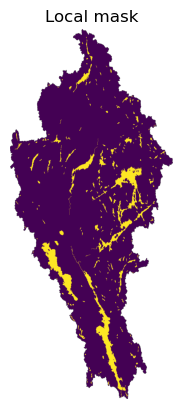

In [9]:
# Quick check of mask for one catchment
geom = cat_gdf_3857.iloc[1].geometry

# get bounding box
xmin, ymin, xmax, ymax = geom.bounds

# open raster to get transform + window
with rasterio.open(ndvi_path) as src:
    window = from_bounds(xmin, ymin, xmax, ymax, src.transform)
    transform_window = src.window_transform(window)

    # slice mask directly
    mask_crop = water_mask[
        int(window.row_off) : int(window.row_off + window.height),
        int(window.col_off) : int(window.col_off + window.width),
    ]

# create mask only for the small window
mask_geom = geometry_mask(
    [geom],
    transform=transform_window,
    invert=True,
    out_shape=mask_crop.shape,
)

local = np.where(mask_geom, mask_crop, np.nan)

plt.imshow(local)
plt.title("Local mask")
plt.axis("off")
plt.show()

## Zonal stats on median NDVI (Band 1)

In [10]:
# statistics to compute (percentiles, min and max only for QC)
ndvi_stats_li = [
    "mean",
    "std",
    "percentile_5",
    "percentile_95",
    "min",
    "max",
]

ndvi_gdf = cat_gdf_3857[["site_code", "Name", "geometry"]].copy()

ndvi_gdf, ndvi_stat_cols = compute_zonal_stats(
    cat_gdf=ndvi_gdf,
    raster_path=ndvi_path,
    stats_list=ndvi_stats_li,
    cat_id_col=cat_id_col,
    prefix="s2-ndvi-summer",
    band=1,
    mask_array=water_mask,
    mask_mode="exclude",  # exclude: drop pixels where mask==1
)

ndvi_gdf[ndvi_stat_cols].describe()

/opt/conda/lib/python3.13/site-packages/rasterstats/io.py:335: NodataWarning: Setting nodata to -999; specify nodata explicitly
  warnings.warn(


s2-ndvi-summer: 0/8482 catchments have <0.0 proportion valid pixels (0.0%), replaced stats with NaNs
s2-ndvi-summer: 0 catchments with no valid pixels


,s2-ndvi-summer_mean,s2-ndvi-summer_std,s2-ndvi-summer_percentile_5,s2-ndvi-summer_percentile_95,s2-ndvi-summer_min,s2-ndvi-summer_max
count,8482.000000,8482.000000,8482.000000,8482.000000,8482.000000,8482.000000
mean,0.711635,0.121249,0.479922,0.850830,0.053402,0.905942
std,0.099523,0.061023,0.197697,0.034700,0.223230,0.023584
min,0.095443,0.026822,-0.058324,0.406546,-1.000000,0.703157
25%,0.684399,0.077594,0.383699,0.836607,-0.022985,0.896852
50%,0.743005,0.101032,0.556921,0.855896,0.058696,0.910554
75%,0.773254,0.149236,0.622003,0.873367,0.184558,0.920302
max,0.867275,0.361559,0.804072,0.922360,0.689711,1.000000


In [14]:
ndvi_gdf.loc[ndvi_gdf['s2-ndvi-summer_percentile_5'] < 0]

,site_code,Name,geometry,s2-ndvi-summer_mean,s2-ndvi-summer_std,s2-ndvi-summer_percentile_5,s2-ndvi-summer_percentile_95,s2-ndvi-summer_min,s2-ndvi-summer_max,s2-ndvi-summer_valid_frac,total_count
105,002-104118,Mjølkedøla,"POLYGON ((912068.614 8730778.152, 912566.218 8...",0.180803,0.185638,-0.031356,0.558872,-0.212578,0.823441,0.890623,60305
219,002-115578,Muru ved Gjende,"POLYGON ((942567.191 8757680.678, 942858.699 8...",0.211514,0.231720,-0.031811,0.670362,-0.317460,0.879810,0.955200,134553
220,002-115579,Leirungsåe ved Gjende,"POLYGON ((969949.916 8738555.085, 969991.47 87...",0.333295,0.247150,-0.002263,0.718614,-0.369156,0.878818,0.970069,160902
221,002-115580,Knutsholsåe ved Gjende,"POLYGON ((951821.529 8731861.63, 951987.541 87...",0.128241,0.158467,-0.033064,0.433933,-0.265041,0.828238,1.000000,14168
289,002-119369,Mjølkedøla,"POLYGON ((912068.614 8730778.152, 912566.218 8...",0.161590,0.168382,-0.032243,0.483062,-0.212578,0.820849,0.884870,57283
...,...,...,...,...,...,...,...,...,...,...,...
8198,208-102580,Steinelva (St07),"POLYGON ((2388280.91 11039775.033, 2388569.46 ...",0.271534,0.245310,-0.014489,0.827941,-0.124499,0.910471,1.000000,4903
8199,208-102582,Tverrelva (St09),"POLYGON ((2393257.573 11042106.594, 2393430.74...",0.183581,0.172590,-0.007158,0.571461,-0.156550,0.811129,0.897973,15094
8205,208-106805,NSt26 bekk ved Mettevolltunnelen vest,"POLYGON ((2387928.518 11039754.086, 2387986.22...",0.385412,0.302360,-0.000979,0.861722,-0.049198,0.894271,1.000000,2357
8206,208-106806,NSt27 bekk ved Mettevolltunnelen vest,"POLYGON ((2387928.518 11039754.086, 2387986.22...",0.381482,0.301701,-0.001687,0.860851,-0.049198,0.894271,1.000000,2322


In [11]:
# Save
ndvi_fpath = os.path.join(out_folder, f"{catchment_set}_stats_static_ndvi.csv")

# Drop valid fraction and total count - instead use ndvi count data for QC
ndvi_gdf.drop(["s2-ndvi-summer_valid_frac", "total_count", "geometry"], axis=1).to_csv(ndvi_fpath, index=False)

ndvi_gdf.head()

,site_code,Name,geometry,s2-ndvi-summer_mean,s2-ndvi-summer_std,s2-ndvi-summer_percentile_5,s2-ndvi-summer_percentile_95,s2-ndvi-summer_min,s2-ndvi-summer_max,s2-ndvi-summer_valid_frac,total_count
0,001-119928,Oppstrøms Bommen RA,"POLYGON ((1283045.207 8415121.357, 1283204.909...",0.743196,0.080988,0.594708,0.837795,-0.008643,0.912420,0.917595,1587885
1,001-119929,Nedstrøms Bommen RA,"POLYGON ((1283045.207 8415121.357, 1283204.909...",0.743165,0.081065,0.594546,0.837811,-0.008643,0.912420,0.917597,1588751
2,001-30653,YSTE YSTEHEDEBEKKEN,"POLYGON ((1278275.423 8199705.751, 1278508.1 8...",0.733258,0.094689,0.551792,0.861122,0.176465,0.904451,1.000000,10109
3,001-30683,"Unnebergbekken, UNNE","POLYGON ((1261762.211 8222146.382, 1261801.102...",0.703168,0.158880,0.375883,0.858005,-0.043615,0.918342,1.000000,23310
4,001-30687,ØRB2 ØRBEKKEN,"POLYGON ((1292599.008 8187175.769, 1292597.043...",0.752074,0.073738,0.611978,0.835549,0.111593,0.911715,0.817746,63675


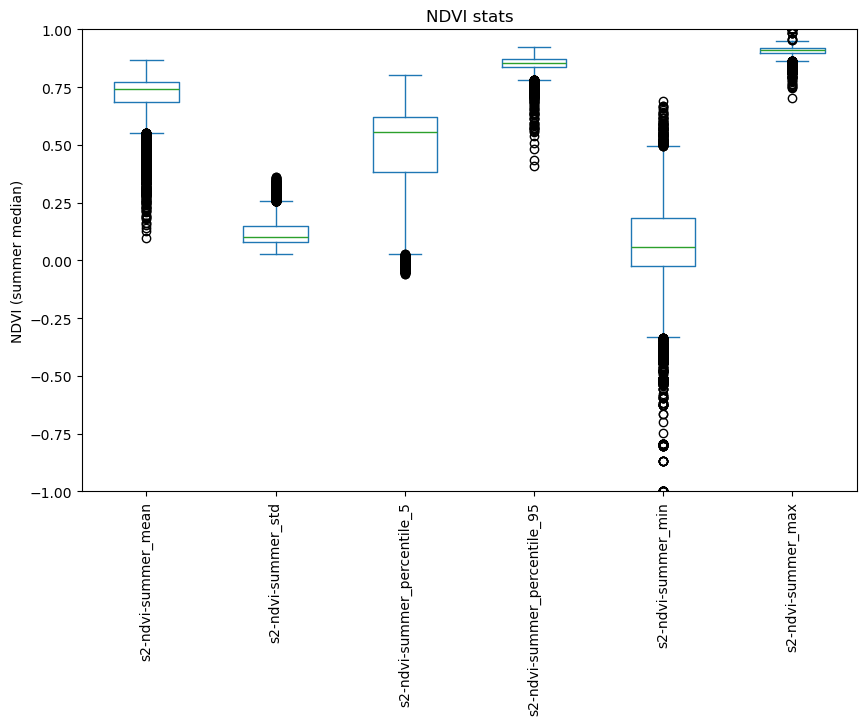

In [16]:
ndvi_gdf[ndvi_stat_cols].plot(kind="box", figsize=(10, 6))
plt.title("NDVI stats")
plt.xticks(rotation=90)
plt.ylabel("NDVI (summer median)")
plt.ylim(ymax=1, ymin=-1)
plt.show()

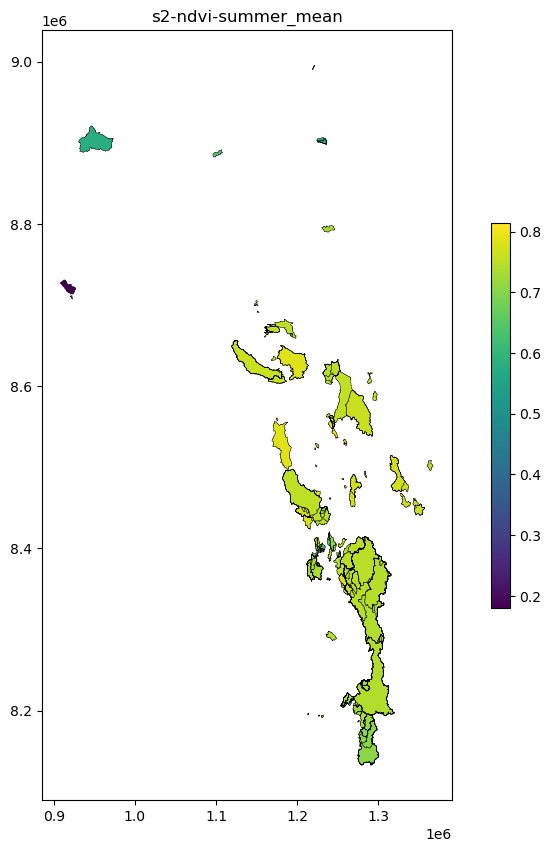

In [25]:
col = "s2-ndvi-summer_mean"
n_catchs = 200

fig, ax = plt.subplots(figsize=(10, 10))
ndvi_gdf[:n_catchs].plot(column=col, ax=ax, legend=True, cmap='viridis', legend_kwds={"shrink": 0.5, "aspect": 20})
ndvi_gdf[:n_catchs].boundary.plot(ax=ax, color="black", linewidth=0.3)

plt.title(col)
plt.show()

# Old/unused

In [13]:
# v1
# statistics to compute
slope_stats_list = [
    "mean",
    "std",
    "median",
    "percentile_5",
    "percentile_95",
    "min",
    "max",
]

t0 = time.perf_counter()

slope_gdf = cat_gdf[["site_code", "Name", "geometry"]].copy()

slope_gdf, slope_stat_cols = compute_zonal_stats(
    cat_gdf=slope_gdf,
    raster_path=slp_path,
    stats_list=slope_stats_list,
    cat_id_col=cat_id_col,
    land_geom=None,
    prefix="slope_deg",
    buffer=1000,
    min_frac=0,  # If 0, don't remove any
    use_land_mask=False,
    plot=False,
    threshold_stats=[
        {"name": "lt2", "op": "lt", "value": 2},
        {"name": "lt5", "op": "lt", "value": 5},
    ],
)

t1 = time.perf_counter()
print(f"Time: {t1 - t0:.2f}s")

# print(slope_stat_cols)
# slope_gdf[[cat_id_col]+slope_stat_cols]
slope_gdf.describe()

slope_deg: 0/8482 below threshold (0.0%)
Time: 829.94s


,slope_deg_mean,slope_deg_std,slope_deg_median,slope_deg_percentile_5,slope_deg_percentile_95,slope_deg_min,slope_deg_max,slope_deg_valid_frac,total_count,slope_deg_lt2_frac,slope_deg_lt2_count,slope_deg_lt5_frac,slope_deg_lt5_count
count,8482.000000,8482.000000,8482.000000,8482.000000,8482.000000,8482.000000,8482.000000,8482.0,8.482000e+03,8482.000000,8.482000e+03,8482.000000,8.482000e+03
mean,10.065361,6.795767,8.812694,1.439237,23.047592,0.107592,41.500217,1.0,2.325365e+05,0.134762,3.942154e+04,0.346298,9.367492e+04
std,5.119060,3.056756,5.054152,1.351685,10.426684,0.330414,17.287698,0.0,1.296713e+06,0.127100,2.508415e+05,0.210921,5.888474e+05
min,0.267214,0.140680,0.241600,0.000000,0.543929,0.000000,0.849482,1.0,2.040000e+02,0.000000,0.000000e+00,0.000000,0.000000e+00
25%,6.575060,4.597847,5.527552,0.577147,15.581865,0.000366,28.409079,1.0,1.425500e+03,0.054656,1.170000e+02,0.188251,4.060000e+02
50%,9.031576,6.312063,7.723657,1.114937,21.263213,0.009759,39.698561,1.0,5.540000e+03,0.098745,5.730000e+02,0.306257,1.651000e+03
75%,12.410881,8.545497,10.854679,1.879886,29.140308,0.089316,54.461712,1.0,3.245775e+04,0.164584,3.716500e+03,0.451613,9.485500e+03
max,40.554992,21.446125,43.701828,24.772667,69.626595,8.797161,81.272041,1.0,2.608850e+07,1.000000,4.827825e+06,1.000000,1.183633e+07


In [8]:
# # ----------------------------
# # Reproject catchments too
# # ----------------------------
# print("Reprojecting...")
# cat_cea = cat_gdf.to_crs({"proj": "cea"})

# # ----------------------------
# # Spatial join + intersection
# # ----------------------------
# print("Intersecting...")

# joined = gpd.sjoin(
#     ar50_cea,
#     cat_cea[[cat_id_col, "geometry"]],
#     how="inner",
#     predicate="intersects",
# )

# joined = joined.merge(
#     cat_cea[[cat_id_col, "geometry"]],
#     on=cat_id_col,
#     suffixes=("", "_cat"),
# )

# joined["area_km2"] = joined.geometry.intersection(joined["geometry_cat"]).area / 1e6

# # ----------------------------
# # Aggregate
# # ----------------------------
# print("Aggregating...")

# lc_df = joined.groupby([cat_id_col, "artype"])["area_km2"].sum().unstack(fill_value=0)

# lc_df.columns = [f"ar50_{c}_km2" for c in lc_df.columns]
# lc_df = lc_df.reset_index()

# # ----------------------------
# # Merge back
# # ----------------------------
# print("Merging...")

# cat_gdf = cat_gdf.merge(lc_df, on=cat_id_col, how="left")

# lc_cols = [c for c in cat_gdf.columns if c.startswith("ar50_") and c.endswith("_km2")]
# cat_gdf[lc_cols] = cat_gdf[lc_cols].fillna(0)

# # ----------------------------
# # Other
# # ----------------------------
# cat_gdf["ar50_other_km2"] = (cat_gdf["area_km2"] - cat_gdf[lc_cols].sum(axis=1)).clip(
#     lower=0
# )

# # ----------------------------
# # Percentages
# # ----------------------------
# print("Converting to percentages...")

# all_area_cols = lc_cols + ["ar50_other_km2"]

# cat_gdf[[c.replace("_km2", "_pct") for c in all_area_cols]] = 100 * cat_gdf[
#     all_area_cols
# ].div(cat_gdf["area_km2"], axis=0)

# cat_gdf.drop(columns=all_area_cols, inplace=True)

# cat_gdf.head()

In [7]:
# cat_cea = cat_gdf.to_crs({"proj": "cea"})
# cat_sindex = cat_cea.sindex

# results = []
# for idx, row in tqdm(
#     cat_cea.iterrows(), total=len(cat_cea), desc="Processing catchments"
# ):
#     geom = row.geometry
#     code = row.site_code
#     row_gdf = cat_cea.iloc[[idx]]

#     # Pre-filter
#     possible_idx = list(ar50_sindex.intersection(geom.bounds))
#     subset = ar50_cea.iloc[possible_idx]
#     if subset.empty:
#         continue

#     # Clip
#     clipped = gpd.clip(subset, geom)
#     if clipped.empty:
#         continue

#     # Calculate area
#     clipped["area_km2"] = clipped.geometry.area / 1e6

#     # Aggregate
#     grouped = clipped.groupby("artype")["area_km2"].sum()

#     # Proportions
#     proportions = 100 * grouped / grouped.sum()

#     # Tidy
#     prop_df = proportions.reset_index(name="pct")
#     prop_df["site_code"] = code

#     results.append(prop_df)

# # Combine
# prop_df = pd.concat(results, ignore_index=True)

# # Reshape
# prop_df = prop_df.pivot(index="site_code", columns="artype", values="pct").fillna(0)

# # Merge
# cat_lc_gdf = pd.merge(cat_gdf, prop_df, how="left", on="site_code")

# # Save
# lu_fpath = os.path.join(out_folder, f"{catchment_set}_stats_static_lu.csv")
# cat_lc_gdf.drop("geometry", axis=1).to_csv(lu_fpath, index=False)

# cat_lc_gdf.head()

In [11]:
# def compute_zonal_stats_old(
#     cat_gdf,
#     raster_path,
#     stats_list,
#     # cat_id_col,
#     land_geom=None,
#     prefix="",
#     buffer=1000,  # for cropping raster; metres
#     min_frac=0.8,  # mask catchments where n_valid/n_tot < this
#     use_land_mask=False,
#     plot=False,
#     threshold_stats=None,   # compute % of polygon area < or > some theshold?
# ):
#     """
#     Compute zonal statistics for polygons from a raster, with optional land masking
#     and optional threshold-based area fractions. The function:
#     1. Crops the raster to the polygon extent (+ buffer)
#     2. Optionally masks out non-land pixels
#     3. Computes standard zonal statistics using rasterstats
#     4. Computes the fraction of valid pixels per polygon
#     5. Optionally computes fractions of area meeting value thresholds
#     6. Masks results for polygons with low data coverage

#     Parameters
#     ----------
#     cat_gdf : GeoDataFrame
#         Polygon dataset (e.g. catchments)
#     raster_path : str
#         Path to input raster
#     stats_list : list of str
#         Statistics to compute (e.g. ["mean", "median", "std"])
#     # cat_id_col : str
#     #     Column containing unique polygon identifiers (used for reporting)
#     land_geom : shapely geometry, optional
#         Land polygon used to mask out sea areas
#     prefix : str, optional
#         Prefix for output column names
#     buffer : float, optional
#         Buffer (in CRS units, typically metres) added before raster cropping
#     min_frac : float, optional
#         Minimum fraction of valid pixels required; polygons below this are masked
#     use_land_mask : bool, optional
#         If True, restrict analysis to land pixels only
#     plot : bool, optional
#         If True, plot fraction of valid pixels
#     threshold_stats : list of dicts, optional
#         List of threshold definitions for area fractions. Each dict should contain:
#             {"name": str, "op": "lt|le|gt|ge", "value": float}
#         Example:
#             [{"name": "lt0", "op": "lt", "value": 0}]

#     Returns
#     -------
#     cat_gdf : GeoDataFrame
#         Input GeoDataFrame with added columns
#     stat_cols : list of str
#         Names of computed primary statistic columns (from stats_list)

#     Notes
#     -----
#     - Fractions (valid_frac, threshold fractions) are computed relative to:
#         * land pixels if use_land_mask=True
#         * all valid raster pixels otherwise
#     - Threshold statistics produce:
#         prefix_{name}_count : number of pixels meeting condition
#         prefix_{name}_frac  : fraction of polygon area meeting condition
#     """

#     def get_valid_mask(arr, nodata):
#         """Return boolean mask of valid pixels."""
#         if nodata is None:
#             return ~np.isnan(arr)
#         else:
#             # also guard against NaNs even if nodata is set
#             return (arr != nodata) & ~np.isnan(arr)


#     # --- 1. Crop raster ---
#     xmin, ymin, xmax, ymax = cat_gdf.total_bounds
#     xmin -= buffer
#     ymin -= buffer
#     xmax += buffer
#     ymax += buffer

#     with rasterio.open(raster_path) as src:
#         window = from_bounds(xmin, ymin, xmax, ymax, src.transform)
#         rast = src.read(1, window=window)
#         transform = src.window_transform(window)
#         nodata = src.nodata

#     # --- 2. Optional land mask ---
#     if use_land_mask:
#         if land_geom is None:
#             raise ValueError("land_geom must be provided when use_land_mask=True")

#         mask_arr = geometry_mask(
#             [land_geom],
#             transform=transform,
#             invert=True,
#             out_shape=rast.shape
#         )

#         rast_used = np.where(mask_arr, rast, nodata)

#         # Denominator = land pixels only
#         # ones = np.where(mask_arr, 1, 0).astype(np.int16)
#         valid_mask = get_valid_mask(rast, nodata)
#         ones = valid_mask.astype(np.int16)

#         nodata_ones = 0

#     else:
#         rast_used = rast

#         # denominator = all valid raster pixels
#         ones = np.where(rast != nodata, 1, 0).astype(np.int16)
#         nodata_ones = 0

#     # --- 3. Zonal stats on raster ---
#     stats = zonal_stats(
#         cat_gdf,
#         rast_used,
#         affine=transform,
#         stats=stats_list + ["count"],
#         nodata=nodata
#     )

#     for stat in stats_list:
#         cat_gdf[f"{prefix}_{stat}"] = [s.get(stat) for s in stats]

#     cat_gdf["valid_count"] = [s["count"] for s in stats]

#     # --- 4. Total pixel count ---
#     total_counts = zonal_stats(
#         cat_gdf,
#         ones,
#         affine=transform,
#         stats=["sum"],
#         nodata=nodata_ones
#     )

#     cat_gdf["total_count"] = [s["sum"] for s in total_counts]

#     # --- 4b. Threshold-based stats ---
#     if threshold_stats is not None:
#         for ts in threshold_stats:
#             name = ts["name"]
#             op = ts["op"]
#             value = ts["value"]

#             # Build condition
#             if op == "lt":
#                 cond = rast_used < value
#             elif op == "le":
#                 cond = rast_used <= value
#             elif op == "gt":
#                 cond = rast_used > value
#             elif op == "ge":
#                 cond = rast_used >= value
#             else:
#                 raise ValueError(f"Invalid threshold op: {op}")

#             # Exclude nodata
#             # valid_mask = (rast_used != nodata)
#             # cond = cond & valid_mask
#             valid_mask = get_valid_mask(rast_used, nodata)
#             cond = cond & valid_mask

#             cond_arr = cond.astype(np.int16)

#             cond_counts = zonal_stats(
#                 cat_gdf,
#                 cond_arr,
#                 affine=transform,
#                 stats=["sum"],
#                 nodata=0
#             )

#             count_col = f"{prefix}_{name}_count"
#             frac_col = f"{prefix}_{name}_frac"

#             cat_gdf[count_col] = [s["sum"] for s in cond_counts]
#             cat_gdf[frac_col] = cat_gdf[count_col] / cat_gdf["total_count"]

#             cat_gdf.loc[cat_gdf["total_count"] == 0, frac_col] = np.nan

#     # Make stats cols list
#     stat_cols = [f"{prefix}_{s}" for s in stats_list]
#     if threshold_stats is not None:
#         stat_cols += [f"{prefix}_{ts['name']}_frac" for ts in threshold_stats]

#     # --- 5. Valid fraction ---
#     cat_gdf[f"{prefix}_valid_frac"] = cat_gdf["valid_count"] / cat_gdf["total_count"]
#     cat_gdf.loc[cat_gdf["total_count"] == 0, f"{prefix}_valid_frac"] = np.nan

#     # --- 6. Report ---
#     n_invalid = np.sum(cat_gdf[f"{prefix}_valid_frac"] < min_frac)
#     n_total = len(cat_gdf)

#     # invalid_ids = cat_gdf.loc[cat_gdf[f"{prefix}_valid_frac"] < min_frac, cat_id_col]

#     frac = n_invalid / n_total if n_total > 0 else np.nan
#     print(f"{prefix}: {frac} below threshold ({frac:.1%})")

#     # --- 7. Plot ---
#     if plot:
#         fig, ax = plt.subplots(figsize=(15, 15))
#         cat_gdf.plot(
#             column=f"{prefix}_valid_frac",
#             legend=True,
#             ax=ax,
#             legend_kwds={"shrink": 0.5, "aspect": 20}
#         )
#         cat_gdf.boundary.plot(ax=ax, color="black", linewidth=0.3)
#         plt.title(f"{prefix}: fraction of valid pixels")
#         plt.show()

#     # --- 8. Mask bad catchments ---
#     cat_gdf.loc[cat_gdf[f"{prefix}_valid_frac"] < min_frac, stat_cols] = np.nan

#     return cat_gdf, stat_cols

In [11]:
# # V2 (used for first estimate of slope)

# def compute_zonal_stats(
#     cat_gdf,
#     raster_path,
#     stats_list,
#     cat_id_col,
#     prefix="",
#     buffer=1000,
#     min_frac=0.8,
#     use_land_mask=False,
#     land_geom=None,
#     threshold_stats=None,
#     mask_array=None,  # e.g. agriculture mask
#     mask_mode="exclude",  # "exclude" (non-ag) or "include" (ag)
#     plot=False,
# ):
#     # ----------------------------
#     # Helpers
#     # ----------------------------
#     def cname(p, s):
#         return f"{p}_{s}" if p else s

#     def valid_mask(arr, nodata):
#         if nodata is None:
#             return ~np.isnan(arr)
#         return (~np.isnan(arr)) & (arr != nodata)

#     # ----------------------------
#     # 1. Read raster subset
#     # ----------------------------
#     xmin, ymin, xmax, ymax = cat_gdf.total_bounds
#     xmin -= buffer
#     ymin -= buffer
#     xmax += buffer
#     ymax += buffer

#     with rasterio.open(raster_path) as src:
#         window = from_bounds(xmin, ymin, xmax, ymax, src.transform)
#         raster = src.read(1, window=window)
#         transform = src.window_transform(window)
#         nodata = src.nodata

#         if mask_array is not None:
#             row_off = int(window.row_off)
#             col_off = int(window.col_off)
#             h = int(window.height)
#             w = int(window.width)

#             mask_window = mask_array[row_off : row_off + h, col_off : col_off + w]
#         else:
#             mask_window = None

#     # ----------------------------
#     # 2. Apply land mask (base mask ONLY)
#     # ----------------------------
#     raster_base = raster.copy()

#     if use_land_mask:
#         from rasterio.features import geometry_mask

#         if land_geom is None:
#             raise ValueError("land_geom required when use_land_mask=True")

#         land_mask = geometry_mask(
#             [land_geom],
#             transform=transform,
#             invert=True,
#             out_shape=raster.shape,
#         )

#         raster_base = np.where(land_mask, raster_base, nodata)

#     # ----------------------------
#     # 3. Zonal stats on BASE raster (for denominator)
#     # ----------------------------
#     zs_base = zonal_stats(
#         cat_gdf,
#         raster_base,
#         affine=transform,
#         stats=["count"],
#         nodata=nodata,
#         raster_out=False,  # faster
#     )

#     # extract per-catchment denominator (terrestrial pixels)
#     total_base_arr = np.array([s.get("count", 0) for s in zs_base])

#     # ----------------------------
#     # 4. Apply analysis mask (ag / non-ag)
#     # ----------------------------
#     raster_used = raster_base.copy()

#     if mask_window is not None:
#         if mask_mode == "exclude":  # keep non-ag
#             raster_used = np.where(mask_window == 0, raster_used, nodata)
#         else:  # keep ag only
#             raster_used = np.where(mask_window != 0, raster_used, nodata)

#     # ----------------------------
#     # 5. Zonal stats (main calculation)
#     # ----------------------------
#     zs = zonal_stats(
#         cat_gdf,
#         raster_used,
#         affine=transform,
#         stats=stats_list,
#         nodata=nodata,
#         raster_out=True,
#     )

#     # threshold operators
#     if threshold_stats is not None:
#         ops = {
#             "lt": np.less,
#             "le": np.less_equal,
#             "gt": np.greater,
#             "ge": np.greater_equal,
#         }

#     results = []

#     # ----------------------------
#     # 6. Per-polygon processing
#     # ----------------------------
#     for i, s in enumerate(zs):
#         row = {}

#         arr = s.get("mini_raster_array")
#         total_base = total_base_arr[i]

#         # ---- basic stats (already masked raster)
#         for stat in stats_list:
#             row[stat] = s.get(stat)

#         if arr is None or total_base == 0:
#             row["valid_frac"] = np.nan

#         else:
#             vm = valid_mask(arr, nodata)

#             # fraction of valid masked pixels (diagnostic)
#             total_masked = vm.sum()
#             row["valid_frac"] = total_masked / total_base if total_base > 0 else np.nan

#             # ------------------------
#             # Threshold stats (correct denominator)
#             # ------------------------
#             if threshold_stats is not None:
#                 for ts in threshold_stats:
#                     name = ts["name"]

#                     cond = ops[ts["op"]](arr, ts["value"]) & vm
#                     cnt = cond.sum()

#                     # ✅ use TOTAL land pixels (not masked subset)
#                     row[f"{name}_count"] = cnt
#                     row[f"{name}_frac"] = cnt / total_base if total_base > 0 else np.nan

#         row["total_count"] = total_base
#         results.append(row)

#     # ----------------------------
#     # 7. Assign outputs
#     # ----------------------------
#     for stat in stats_list:
#         cat_gdf[cname(prefix, stat)] = [r[stat] for r in results]

#     cat_gdf[cname(prefix, "valid_frac")] = [r["valid_frac"] for r in results]

#     cat_gdf["total_count"] = [r["total_count"] for r in results]

#     if threshold_stats is not None:
#         for ts in threshold_stats:
#             name = ts["name"]

#             cat_gdf[cname(prefix, f"{name}_frac")] = [
#                 r.get(f"{name}_frac") for r in results
#             ]
#             cat_gdf[cname(prefix, f"{name}_count")] = [
#                 r.get(f"{name}_count") for r in results
#             ]

#     # ----------------------------
#     # 8. Apply min_frac filter
#     # ----------------------------
#     vf_col = cname(prefix, "valid_frac")
#     bad = cat_gdf[vf_col] < min_frac

#     stat_cols = [cname(prefix, s) for s in stats_list]

#     if threshold_stats is not None:
#         stat_cols += [cname(prefix, f"{ts['name']}_frac") for ts in threshold_stats]

#     cat_gdf.loc[bad, stat_cols] = np.nan

#     # ----------------------------
#     # 9. Reporting
#     # ----------------------------
#     n_total = len(cat_gdf)
#     n_bad = bad.sum()
#     frac = n_bad / n_total if n_total > 0 else np.nan

#     print(f"{prefix}: {n_bad}/{n_total} below threshold ({frac:.1%})")

#     # ----------------------------
#     # 10. Plot
#     # ----------------------------
#     if plot:
#         fig, ax = plt.subplots(figsize=(12, 12))
#         cat_gdf.plot(column=vf_col, legend=True, ax=ax)
#         cat_gdf.boundary.plot(ax=ax, color="black", linewidth=0.3)
#         plt.title(f"{prefix}: valid fraction")
#         plt.show()

#     return cat_gdf, stat_cols